# Tutoriel SLIC avec OpenCV

*Arrigoni Ambroise, Benslimane Sarah, Douagi Selma & Sourdrille Nathan*

## Introduction à SLIC

Ce tutoriel aborde la segmentation d'images couleur par l'algorithme SLIC. Il s'agit de la méthode la plus intéressante pour la génération de superpixels.  
Le **clustering itératif linéaire simple (SLIC) est une méthode de segmentation d'images utilisée pour générée des superpixels**. Le principe même de SLIC est d'exploiter la redondance spatiale et colorimétrique des images.  

Mais commençons par la base, qu'est-ce qu'un superpixel ? Il s'agit tout simplement d'un groupe de pixels voisins qui sont similaires en couleur et proche dans le plan spatial. Autrement dit, on associe des pixels entre eux car ils sont de la même couleur (ou presque) et voisins. Il y a donc deux notions à prendre en compte: la localisation spatiale du pixel et sa couleur. 

### Librairies nécessaires

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.segmentation import slic, mark_boundaries
from skimage import io

### Chargement de l'image 

Tout d'abord, il nous faut choisir une image d'étude. On se pose comme objectif de parvenir à segmenter en superpixels l'image *violet.jpg*. C'est une image interessante car elle possède peu de détails et une certaine redondance dans les couleurs et la forme.

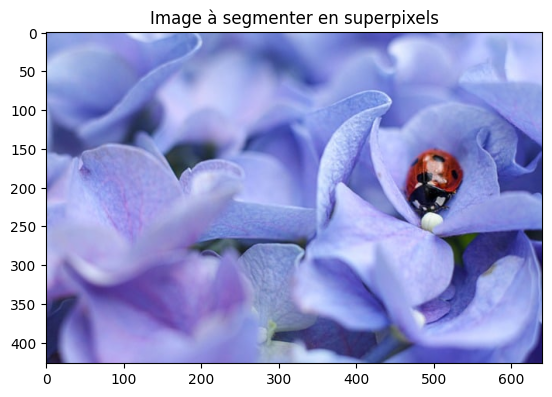

In [2]:
path_images = "../Images_Projet/"
img = cv2.imread(path_images+'violet.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Image à segmenter en superpixels");

*note: il est inutile d'afficher une image dans l'espace lab.*

### Fonctionnement général de l'algorithme SLIC:  
1) Il place des points de départ régulièrement espacés dans l'image, chacun représentant un futur superpixel
2) Il regroupe les pixels autour de ces points en tenant compte de:
    - la couleur 
    - la proximité spatiale
3) Il met à jour les centres des superpixels en recalculant leur centre moyen
4) Il répète ces étapes plusieurs fois jusqu'à ce que les superpixels deviennent stables

Pour comparer ou regrouper des couleurs, avec SLIC notamment, l'espace couleur CIELAB est beaucoup plus fiable que RGB. Il s'agit d'un espace de couleur perceptuellement uniforme, c'est à dire que la distance entre deux couleurs en Lab correspond approximativement à ce que l'oeil voit comme différence de couleur.  
Cet espace dispose de 3 canaux:  
- L: Luminosité; intervalle: [0,100]; 0: noir, 100: blanc
- a: Axe vert/rouge; négatif: vert, positif: rouge
- b: Axe bleu/jaune; négatif: bleu, positif: jaune

Les deux seuls paramètres de SLIC sont (K,m).  
K: nombre de superpixels souhaité
- K petit => moins de superpixels, si l'image a beaucoup de détails
- K grand => plus de superpixels, pour une représentation simplifiée de l'image

m (poids de la compacité): équilibre entre la similarité de couleur et la proximité spatiale, d'où:
- m petit => priorité aux couleurs: les superpixels suivent plutôt les variations de couleur, quitte à devenir irréguliers/ s'étirer. idéal pour préserver des contours précis
- m grand => priorité à la forme régulière: les superpixels deviennent plus carrés et uniformes, l'influence de la proximité spatiale augmente, les frontières suivent moins bien les contours de l'image

### Utilisation de la fonction slic de scikit-image

Pour appliquer l'algorithme SLIC sur une image, on peut utiliser la fonction slic de skimage.segmentation. La fonction prend différents paramètres. Voici les principaux paramètres:
- **img**: il faut nécessairement une image avec 3 canaux (RGB). 
- **n_segments**: K
- **compactness**: m

À titre informatif, voici une explication des autres paramètres possibles:
- max_num_iter: Nombre max d'itérations
- sigma: Flou gaussien appliqué avant l'algorithme SLIC (utile pour réduire le bruit)
- spacing: paramètre pour image volumétriques 3D, inutile pour les images 2D
- convert2lab: Convertit l'image RGB en Lab (par défaut True)
- enforce_connectivity: Assure que chaque superpixel est une région connexe (True par défaut)
- min_size_factor/max_size_factor: taille des superpixels par rapport à la taille moyenne.
- slic_zero: Active la variante SLICO (Slic Zero) qui cherche automatiquement la meilleur compacité
- start_label: label initial des superpixels

Ainsi, on peut simplement appliquer la fonction slic pour obtenirs les différents segments (labels). Pour afficher les superpixels, on doit utiliser la fonction skimage.segmentation.mark_boundaries qui prend en paramètre:

- img: image en format RGB
- label_img: carte des labels (segments)

et qui renvoie l'image avec les contours.

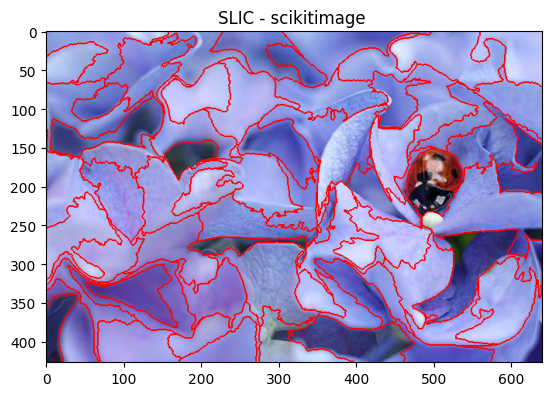

In [3]:
segments = slic(
    img_rgb, n_segments=80, compactness=10)

img_contour = mark_boundaries(img_rgb, segments, color=(1, 0, 0))  
plt.imshow(img_contour)
plt.title("SLIC - scikitimage ");